# Acquire Sentinel-2 monthly composites

Build monthly reflectance and vegetation-index composites, record per-window
quality metrics, and preview a saved result. For the study methods, see the
[Imagery Acquisition and Preparation white paper](../docs/white-papers/Imagery-Acquisition-and-Preparation.md).

Run the notebook from `notebooks/` and execute cells from top to bottom.


In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from shapely.validation import make_valid

from s2grab import S2Client, month_windows
from s2grab.composites import composite_qa
from s2grab.config import AcquisitionConfig
from s2grab.sites import load_aois

ROOT = Path.cwd().parent
assert (ROOT / "pyproject.toml").exists(), "Run notebooks from the notebooks/ folder"
ACQUISITION = AcquisitionConfig.from_yaml(
    ROOT / "configs" / "imagery.yaml", project_root=ROOT
)

client = S2Client()
print("s2grab ready. repo root:", ROOT)


s2grab ready. repo root: /home/tshihadah/code/wadi-gaza-research


/home/tshihadah/code/wadi-gaza-research/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Run configuration

The canonical acquisition settings are in [`configs/imagery.yaml`](../configs/imagery.yaml).
Set `DEMO = True` to run the configured demo month and output directory;
leave it `False` for the full configured study period.


In [2]:
DEMO = False

SITES_SOURCE = ACQUISITION.sites_source
ID_FIELD = ACQUISITION.id_field

MONTHS = list(ACQUISITION.months)
YEARS = list(ACQUISITION.years)
BANDS = list(ACQUISITION.bands)
INDICES = list(ACQUISITION.indices)
RESOLUTION = ACQUISITION.resolution
UPSAMPLING = ACQUISITION.upsampling
MAX_CLOUD = ACQUISITION.max_cloud
MASK_SCL = list(ACQUISITION.mask_scl)
COMPUTE_STD = ACQUISITION.compute_std
SAVI_L = ACQUISITION.savi_l
OUT_DIR = ACQUISITION.output_dir

if DEMO:
    MONTHS = [ACQUISITION.demo_month]
    YEARS = [max(YEARS)]
    OUT_DIR = ACQUISITION.demo_output_dir

print("DEMO:", DEMO)
print("windows:", [(y, m) for y in YEARS for m in MONTHS])
print("product bands:", BANDS, "+ indices:", INDICES)
print("upsampling:", UPSAMPLING)
print("mask SCL:", MASK_SCL)
print("SAVI L:", SAVI_L)
print("output dir:", OUT_DIR)


DEMO: False
windows: [(2019, 1), (2019, 5), (2019, 9), (2019, 11), (2020, 1), (2020, 5), (2020, 9), (2020, 11), (2021, 1), (2021, 5), (2021, 9), (2021, 11), (2022, 1), (2022, 5), (2022, 9), (2022, 11), (2023, 1), (2023, 5), (2023, 9), (2023, 11), (2024, 1), (2024, 5), (2024, 9), (2024, 11), (2025, 1), (2025, 5), (2025, 9), (2025, 11)]
product bands: ['B02', 'B03', 'B04', 'B05', 'B08', 'B8A', 'B11', 'B12'] + indices: ['NDVI', 'GNDVI', 'SAVI', 'NDRE']
upsampling: NEAREST
mask SCL: [0, 1, 2, 3, 7, 8, 9, 10, 11]
output dir: /home/tshihadah/code/wadi-gaza-research/outputs/composites


## 2. Load study sites

Read the site polygons, repair invalid geometries, and build the site grids.


In [3]:
sites = gpd.read_file(SITES_SOURCE)

# Repair any self-intersecting / invalid rings here
invalid = ~sites.geometry.is_valid
if invalid.any():
    print(f"Repairing {int(invalid.sum())} invalid geometr(ies):",
          list(sites.loc[invalid, ID_FIELD]))
    sites.loc[invalid, "geometry"] = sites.loc[invalid, "geometry"].apply(make_valid)

aois = load_aois(
    sites,
    id_field=ID_FIELD,
    resolution=RESOLUTION,
)

print(f"{len(aois)} site(s) loaded")
for name, aoi in list(aois.items())[:10]:
    print(f"  {name}: {aoi}")


Repairing 1 invalid geometr(ies): ['HaBesorNationalPark']
7 site(s) loaded
  AlAhrashProtectorate: AOI(EPSG:32636, 252x195px, 10.0m, polygon)
  BesorStream: AOI(EPSG:32636, 167x224px, 10.0m, polygon)
  HaBesorNationalPark: AOI(EPSG:32636, 273x730px, 10.0m, polygon)
  HolotNizzanim: AOI(EPSG:32636, 669x756px, 10.0m, polygon)
  HolotPalmahim: AOI(EPSG:32636, 244x345px, 10.0m, polygon)
  NahalRubin: AOI(EPSG:32636, 193x102px, 10.0m, polygon)
  WadiGaza: AOI(EPSG:32636, 510x457px, 10.0m, polygon)


## 3. Build monthly windows

Create calendar-month windows from the configured years and months.


In [4]:
windows = month_windows(YEARS, MONTHS)
pd.DataFrame(windows)

,label,year,month,start,end
0,2019-01,2019,1,2019-01-01,2019-01-31
1,2019-05,2019,5,2019-05-01,2019-05-31
2,2019-09,2019,9,2019-09-01,2019-09-30
3,2019-11,2019,11,2019-11-01,2019-11-30
4,2020-01,2020,1,2020-01-01,2020-01-31
5,2020-05,2020,5,2020-05-01,2020-05-31
6,2020-09,2020,9,2020-09-01,2020-09-30
7,2020-11,2020,11,2020-11-01,2020-11-30
8,2021-01,2021,1,2021-01-01,2021-01-31
9,2021-05,2021,5,2021-05-01,2021-05-31


## 4. Fetch composites and calculate QA

For each site and window, save the composite and collect its status and QA
metrics for the manifest.


In [5]:
EMPTY_QA = {"n_scenes": None, "mean_cloud": None,
            "pct_nodata": None, "mean_pixel_std": None}

# Provenance written into every GeoTIFF (footprint rule + pixel count are added
# automatically by Image.save).
PROVENANCE = {
    "SITES_SOURCE": SITES_SOURCE.relative_to(ROOT).as_posix(),
    "REDUCER": "median",
    "MAX_CLOUD_PCT": MAX_CLOUD,
    "MASK_SCL": ",".join(map(str, MASK_SCL)),
    "UPSAMPLING": UPSAMPLING,
    "SAVI_L": SAVI_L,
}

records = []
for site, aoi in aois.items():
    for w in windows:
        try:
            image, qa = composite_qa(
                client, aoi, w["start"], w["end"],
                bands=BANDS, indices=INDICES,
                max_cloud=MAX_CLOUD, mask_scl=MASK_SCL, compute_std=COMPUTE_STD,
                upsampling=UPSAMPLING, savi_l=SAVI_L,
            )
        except Exception as exc:  # keep the run going; log the failure
            records.append({"site": site, "window": w["label"],
                            "status": f"error: {exc}", "path": None, **EMPTY_QA})
            print(f"{site} {w['label']}: ERROR {exc}")
            continue

        if image is None:
            records.append({"site": site, "window": w["label"],
                            "status": "no data", "path": None, **qa})
            print(f"{site} {w['label']}: no data ({qa['n_scenes']} scenes)")
            continue

        path = OUT_DIR / site / f"{site}_{w['label']}.tif"
        image.save(path, tags={**PROVENANCE, "SITE": site, "WINDOW": w["label"],
                               "N_SCENES": qa["n_scenes"]})
        records.append({"site": site, "window": w["label"], "status": "ok",
                        "path": str(path.relative_to(ROOT)), **qa})
        print(f"{site} {w['label']}: {qa['n_scenes']} scenes, "
              f"{qa['pct_nodata']:.1f}% no-data -> {path.name}")

manifest = pd.DataFrame(records)
print(f"\n{len(manifest)} composite(s) attempted")

AlAhrashProtectorate 2019-01: 5 scenes, 0.0% no-data -> AlAhrashProtectorate_2019-01.tif


AlAhrashProtectorate 2019-05: 6 scenes, 0.0% no-data -> AlAhrashProtectorate_2019-05.tif


AlAhrashProtectorate 2019-09: 5 scenes, 0.0% no-data -> AlAhrashProtectorate_2019-09.tif


AlAhrashProtectorate 2019-11: 6 scenes, 0.0% no-data -> AlAhrashProtectorate_2019-11.tif


AlAhrashProtectorate 2020-01: 3 scenes, 0.0% no-data -> AlAhrashProtectorate_2020-01.tif


AlAhrashProtectorate 2020-05: 4 scenes, 0.0% no-data -> AlAhrashProtectorate_2020-05.tif


... (186 outputs left out)

WadiGaza 2025-01: 2 scenes, 0.0% no-data -> WadiGaza_2025-01.tif


WadiGaza 2025-05: 8 scenes, 0.0% no-data -> WadiGaza_2025-05.tif


WadiGaza 2025-09: 8 scenes, 0.0% no-data -> WadiGaza_2025-09.tif


WadiGaza 2025-11: 5 scenes, 0.0% no-data -> WadiGaza_2025-11.tif

196 composite(s) attempted


## 5. Save the QA manifest

Write one manifest row per attempted site and window.


In [6]:
cols = ["site", "window", "status", "n_scenes", "mean_cloud",
        "pct_nodata", "mean_pixel_std", "path"]
manifest = manifest.reindex(columns=cols)

manifest_path = OUT_DIR / "qa_manifest.csv"
manifest_path.parent.mkdir(parents=True, exist_ok=True)
manifest.to_csv(manifest_path, index=False)
print("manifest ->", manifest_path.relative_to(ROOT))
manifest

manifest -> outputs/composites/qa_manifest.csv


,site,window,status,n_scenes,mean_cloud,pct_nodata,mean_pixel_std,path
0,AlAhrashProtectorate,2019-01,ok,5,5.740000,0.0,0.022935,outputs/composites/AlAhrashProtectorate/AlAhra...
1,AlAhrashProtectorate,2019-05,ok,6,3.376667,0.0,0.010255,outputs/composites/AlAhrashProtectorate/AlAhra...
2,AlAhrashProtectorate,2019-09,ok,5,3.064000,0.0,0.010123,outputs/composites/AlAhrashProtectorate/AlAhra...
3,AlAhrashProtectorate,2019-11,ok,6,3.426667,0.0,0.015802,outputs/composites/AlAhrashProtectorate/AlAhra...
4,AlAhrashProtectorate,2020-01,ok,3,2.893333,0.0,0.020400,outputs/composites/AlAhrashProtectorate/AlAhra...
...,...,...,...,...,...,...,...,...
191,WadiGaza,2024-11,ok,5,1.580000,0.0,0.017667,outputs/composites/WadiGaza/WadiGaza_2024-11.tif
192,WadiGaza,2025-01,ok,2,6.450000,0.0,0.015209,outputs/composites/WadiGaza/WadiGaza_2025-01.tif
193,WadiGaza,2025-05,ok,8,1.823750,0.0,0.011591,outputs/composites/WadiGaza/WadiGaza_2025-05.tif
194,WadiGaza,2025-09,ok,8,2.285000,0.0,0.013964,outputs/composites/WadiGaza/WadiGaza_2025-09.tif


## 6. Preview a composite

Preview a true-colour RGB image and NDVI layer from the first successful
composite.


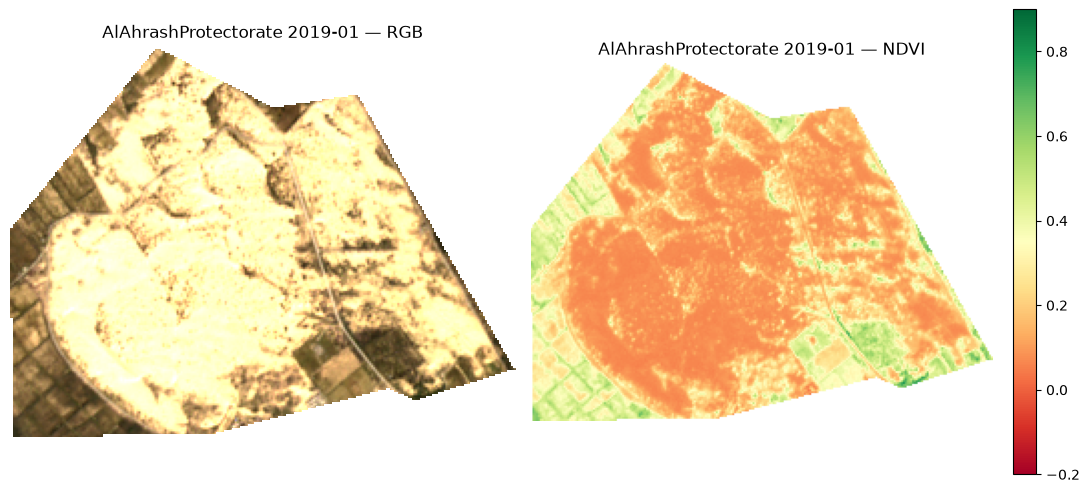

In [7]:
manifest = pd.read_csv(OUT_DIR / "qa_manifest.csv")
band_names = BANDS + INDICES
ok = manifest[manifest["status"] == "ok"]

if ok.empty:
    print("No successful composite to preview.")
else:
    row = ok.iloc[0]
    with rasterio.open(ROOT / row["path"]) as src:
        stack = np.transpose(src.read(), (1, 2, 0))

    def band(name):
        return stack[:, :, band_names.index(name)]

    rgb = np.clip(np.dstack([band("B04"), band("B03"), band("B02")]) / 0.3, 0, 1)

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    axes[0].imshow(rgb)
    axes[0].set_title(f"{row['site']} {row['window']} — RGB")
    im = axes[1].imshow(band("NDVI"), cmap="RdYlGn", vmin=-0.2, vmax=0.9)
    axes[1].set_title(f"{row['site']} {row['window']} — NDVI")
    fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
